# 02. Models, tables, tuning and evaluation

## 1. Objective
Compare model families, measure what the secondary tables add, tune LightGBM, and evaluate the final model once on the untouched hold-out.

## 2. Protocol
80/20 stratified split. 5-fold stratified CV on the 80%. Early stopping on a slice of each **training** fold. The hold-out is used once at the end.

In [1]:
import sys, json, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)
T = '../outputs/tables/'; F = '../outputs/figures/'

## 3. Model families on the same features (set B: application + engineered ratios)

In [2]:
c = pd.read_csv(T + '10_model_comparison_set_B.csv'); c[['model', 'cv_auc_mean', 'cv_auc_std', 'holdout_auc', 'fit_seconds_per_fold']].round(4)

,model,cv_auc_mean,cv_auc_std,holdout_auc,fit_seconds_per_fold
0,Logistic regression,0.7492,0.0030,0.7517,14.4668
1,Random forest,0.7482,0.0024,0.7521,196.4301
2,LightGBM,0.7648,0.0020,0.7697,14.7564
3,XGBoost,0.7636,0.0016,0.7699,26.4305
4,CatBoost,0.7646,0.0019,0.7708,85.7578


Boosting (LightGBM, XGBoost, CatBoost) is about 0.016-0.018 AUC better than logistic regression and random forest; the three boosting libraries are within 0.001 of each other, so the choice among them is not where AUC is won. Random forest needs 13x more time per fold than LightGBM.

In [3]:
f = pd.read_csv(T + '11_cv_fold_auc_set_B.csv'); display(f.pivot(index='fold', columns='model', values='auc').round(4)); print(f.groupby('model').auc.agg(['mean', 'std']).round(4))

model,CatBoost,LightGBM,Logistic regression,Random forest,XGBoost
fold,,,,,
1,0.7638,0.7642,0.7475,0.7470,0.7622
2,0.7621,0.7618,0.7466,0.7457,0.7617
3,0.7654,0.7668,0.7544,0.7496,0.7655
4,0.7673,0.7667,0.7487,0.7516,0.7645
5,0.7643,0.7644,0.7487,0.7470,0.7644


                       mean     std
model                              
CatBoost             0.7646  0.0019
LightGBM             0.7648  0.0020
Logistic regression  0.7492  0.0030
Random forest        0.7482  0.0024
XGBoost              0.7636  0.0016


The spread across folds (standard deviation about 0.002) is much smaller than the gap between model families, so the ranking is reliable.

## 4. Do secondary tables help?

In [4]:
a = pd.read_csv(T + '12_feature_ablation_lightgbm.csv'); a.round(4)

,feature_set,n_features,cv_auc_mean,cv_auc_std,oof_auc,fit_seconds_per_fold,gain_vs_B
0,A: application (raw),121,0.7574,0.0022,0.7574,11.2251,-0.0073
1,B: + engineered ratios,143,0.7648,0.0020,0.7647,14.7774,0.0000
2,B + bureau,277,0.7744,0.0027,0.7744,27.1239,0.0096
3,B + previous_application,386,0.7751,0.0024,0.7750,34.1552,0.0103
4,B + installments_payments,200,0.7754,0.0022,0.7754,20.9522,0.0106
5,B + POS_CASH_balance,177,0.7721,0.0022,0.7720,14.7212,0.0073
6,B + credit_card_balance,220,0.7687,0.0017,0.7687,16.4627,0.0039
7,C: B + all secondary tables,688,0.7895,0.0025,0.7894,81.1760,0.0247


Yes. Engineered ratios add +0.007; bureau, previous applications and instalments add about +0.010 each, POS +0.007 and credit card +0.004; all together +0.025. The gains overlap, so they are not additive.

## 5. Hyper-parameter tuning with Optuna

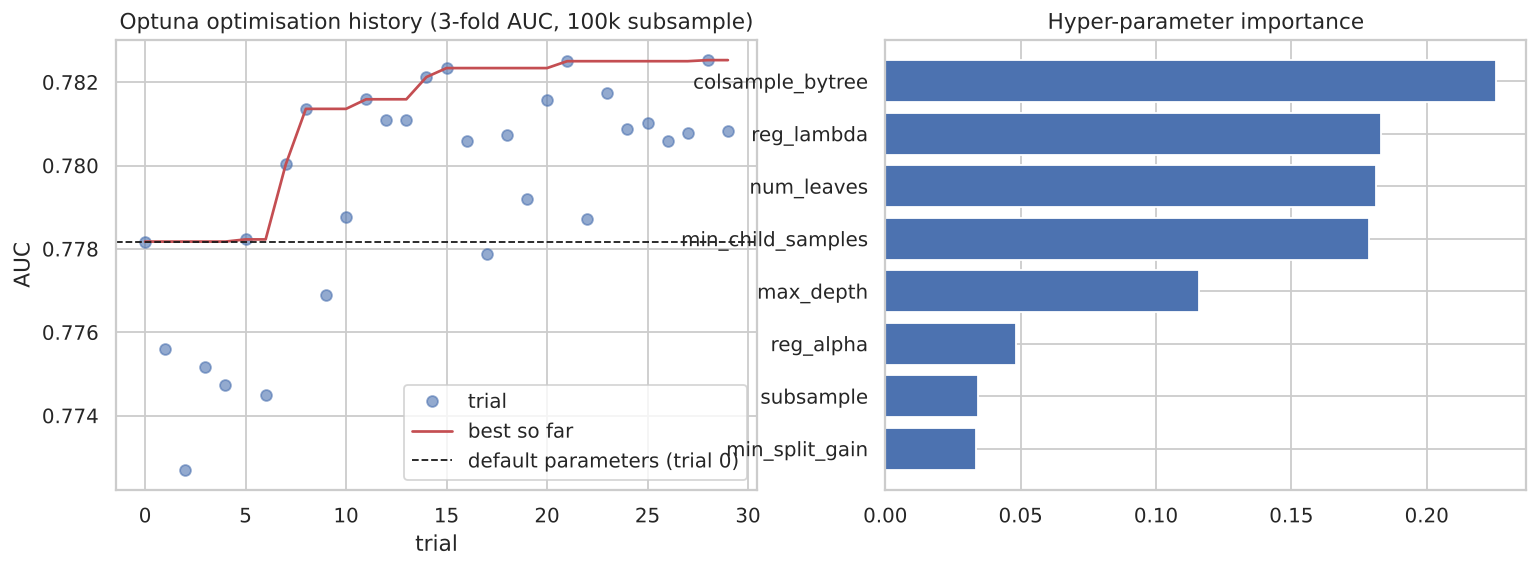

{
 "params": {
  "num_leaves": 17,
  "max_depth": 5,
  "min_child_samples": 81,
  "colsample_bytree": 0.1097938491660616,
  "subsample": 0.8831338288559379,
  "reg_alpha": 0.006157517363094395,
  "reg_lambda": 16.834032129745953,
  "min_split_gain": 0.17072838073683277
 },
 "best_auc_subsample_3fold": 0.7825284281393285,
 "default_auc_subsample_3fold": 0.7781747351782492,
 "best_iter_mean": 297.6666666666667,
 "n_trials": 30
}


In [5]:
display(Image(F + '07_optuna_history_and_importance.png')); print(json.dumps(json.load(open('../outputs/best_params.json')), indent=1))

In [6]:
t = pd.read_csv(T + '13_optuna_trials.csv'); print('trials beating the default parameters:', int((t.value > t.loc[0, 'value']).sum()), 'of', len(t)); print('spread of trial AUCs:', round(t.value.std(), 4))

trials beating the default parameters: 22 of 30
spread of trial AUCs: 0.0027


The tuned model is shallow (5 levels, 17 leaves), samples only about 11% of columns per tree and uses strong L2 regularisation: with 688 features, strong regularisation helps. The improvement over defaults is small.

## 6. Final comparison and hold-out evaluation

,model,features,cv_auc_mean,cv_auc_std,holdout_auc
0,Logistic regression,B (application + engineered),0.7492,0.0030,0.7517
1,Random forest,B (application + engineered),0.7482,0.0024,0.7521
2,LightGBM,B (application + engineered),0.7648,0.0020,0.7697
3,XGBoost,B (application + engineered),0.7636,0.0016,0.7699
4,CatBoost,B (application + engineered),0.7646,0.0019,0.7708
5,LightGBM default,C (all tables),0.7895,0.0025,0.7936
6,LightGBM tuned,C (all tables),0.7929,0.0018,0.7955


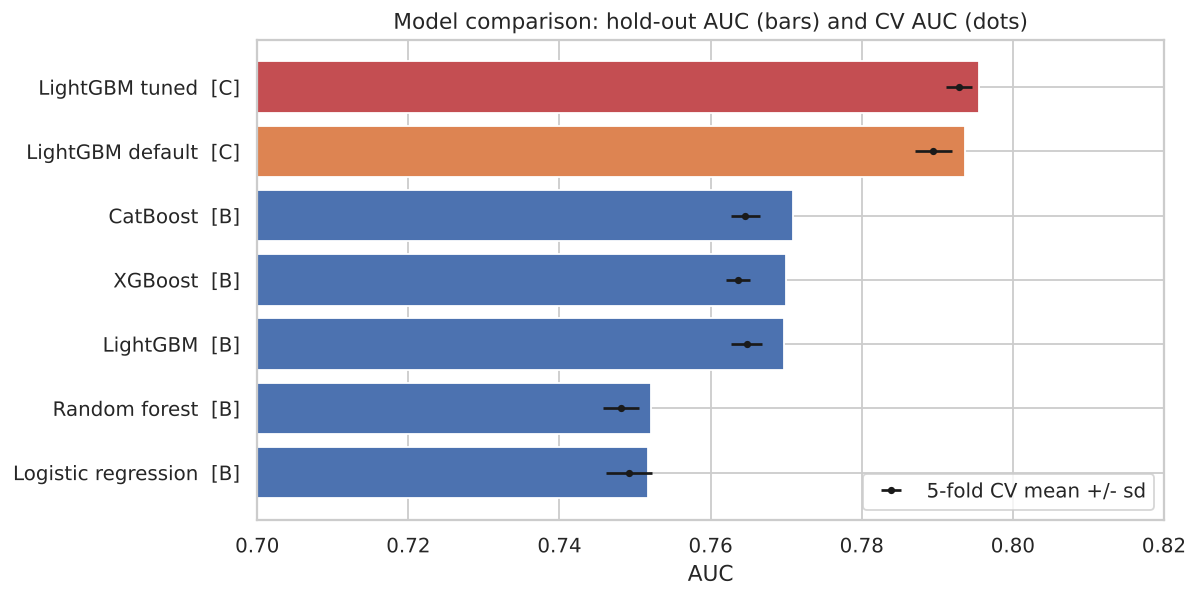

hold-out AUC tuned [point, CI low, CI high]: [0.7955, 0.7894, 0.8019]
tuned - default (paired bootstrap): [0.0019, 0.0003, 0.0034]
Gini 0.591  KS 0.451


In [7]:
display(pd.read_csv(T + '30_final_model_comparison.csv').round(4)); display(Image(F + '18_model_comparison.png'))
s = json.load(open('../outputs/final_summary.json'))
print('hold-out AUC tuned [point, CI low, CI high]:', [round(x, 4) for x in s['holdout_auc']['tuned']])
print('tuned - default (paired bootstrap):', [round(x, 4) for x in s['holdout_auc_diff_tuned_minus_default']])
print('Gini', round(s['gini_tuned'], 3), ' KS', round(s['ks_tuned'], 3))

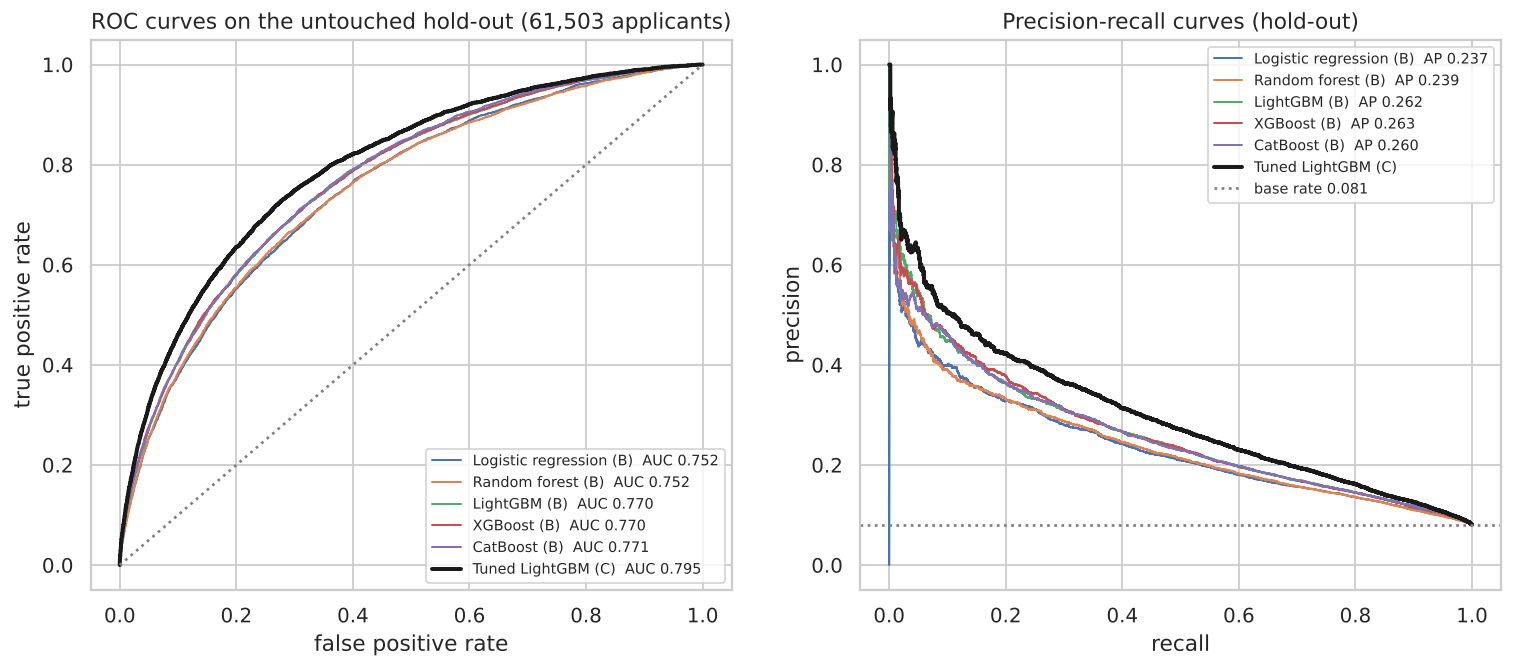

In [8]:
display(Image(F + '08_roc_and_pr_curves_holdout.png'))

## 7. Thresholds and the imbalance problem

,rule,threshold,tp,fp,fn,tn,precision,recall,f1,accuracy,flagged_share
0,max-F1 (chosen on OOF),0.168,2230,5405,2735,51133,0.292,0.449,0.354,0.868,0.124
1,cost-based FN:FP = 5:1 (chosen on OOF),0.165,2275,5580,2690,50958,0.290,0.458,0.355,0.866,0.128
2,flag top 10% riskiest,0.193,1959,4197,3006,52341,0.318,0.395,0.352,0.883,0.100
3,0.5 (naive),0.500,277,191,4688,56347,0.592,0.056,0.102,0.921,0.008


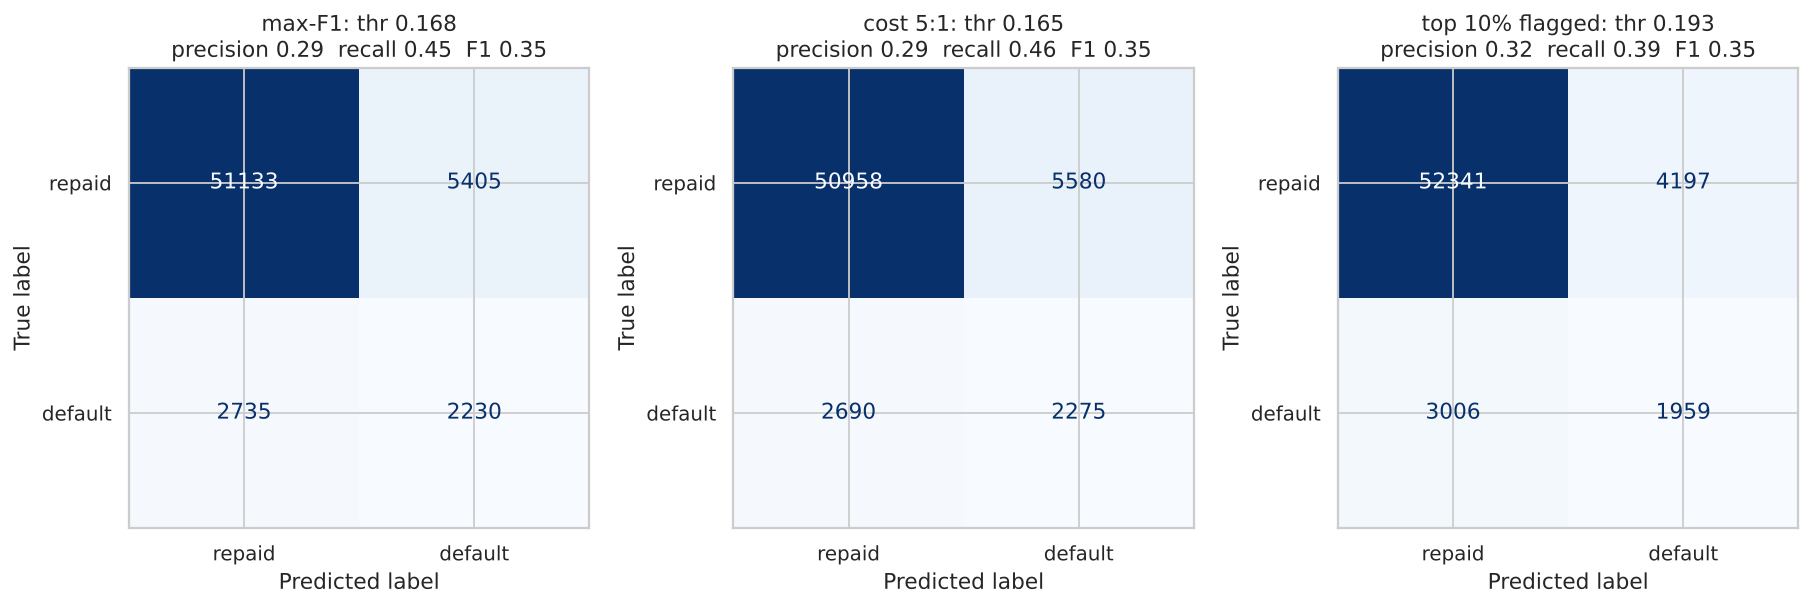

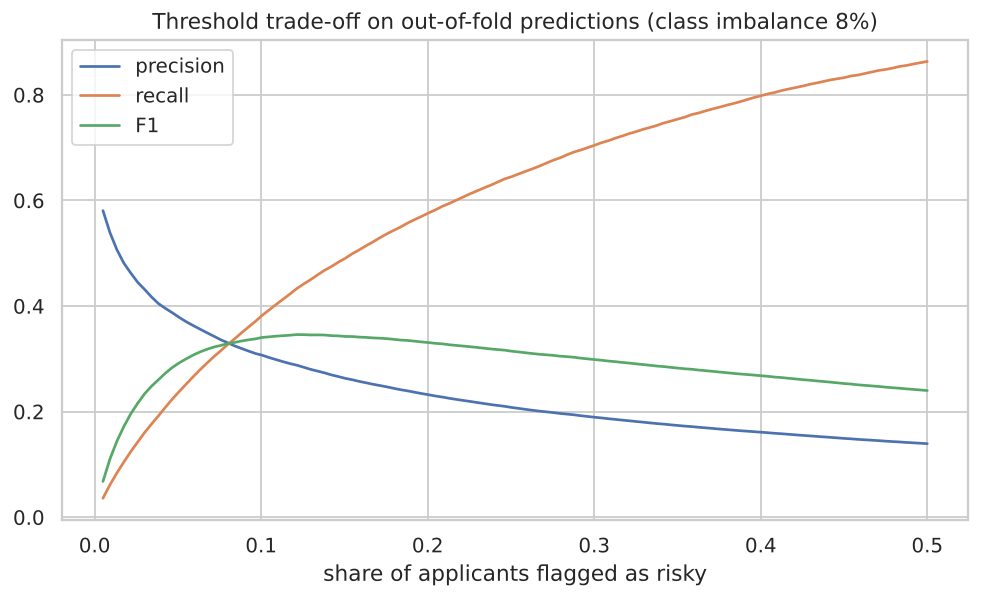

In [9]:
display(pd.read_csv(T + '21_threshold_rules_holdout.csv').round(3)); display(Image(F + '09_confusion_matrices_holdout.png')); display(Image(F + '10_threshold_tradeoff.png'))

At the naive threshold 0.5 accuracy is 92.1% but recall is 5.6%: it looks fine and is useless. Thresholds chosen on out-of-fold data (max-F1 or a 5:1 cost rule) flag about 12% of applicants and catch 45% of defaulters.

## 8. Does rebalancing help?

In [10]:
pd.read_csv(T + '28_class_imbalance_study_set_B.csv').round(4)

,variant,auc,avg_precision,brier,mean_pred,base_rate,best_f1_threshold,best_f1,flagged_share_at_best_f1,recall_at_best_f1,precision_at_best_f1
0,no adjustment,0.7625,0.2459,0.0677,0.0801,0.0807,0.1474,0.3095,0.1461,0.4347,0.2402
1,scale_pos_weight (balanced),0.7166,0.1826,0.0733,0.1007,0.0807,0.1127,0.2675,0.1841,0.4388,0.1924
2,is_unbalance,0.7166,0.1826,0.0733,0.1007,0.0807,0.1127,0.2675,0.1841,0.4388,0.1924
3,undersample majority 3:1,0.7606,0.2427,0.0948,0.2193,0.0807,0.4038,0.3063,0.1461,0.4303,0.2378


No: class weights lower AUC and inflate predicted risk (mean 10% vs actual 8%), undersampling inflates it to 22%, and neither improves the best F1. For ranking and calibrated probabilities the plain model is better; adjust the threshold instead.

## 9. Calibration and lift

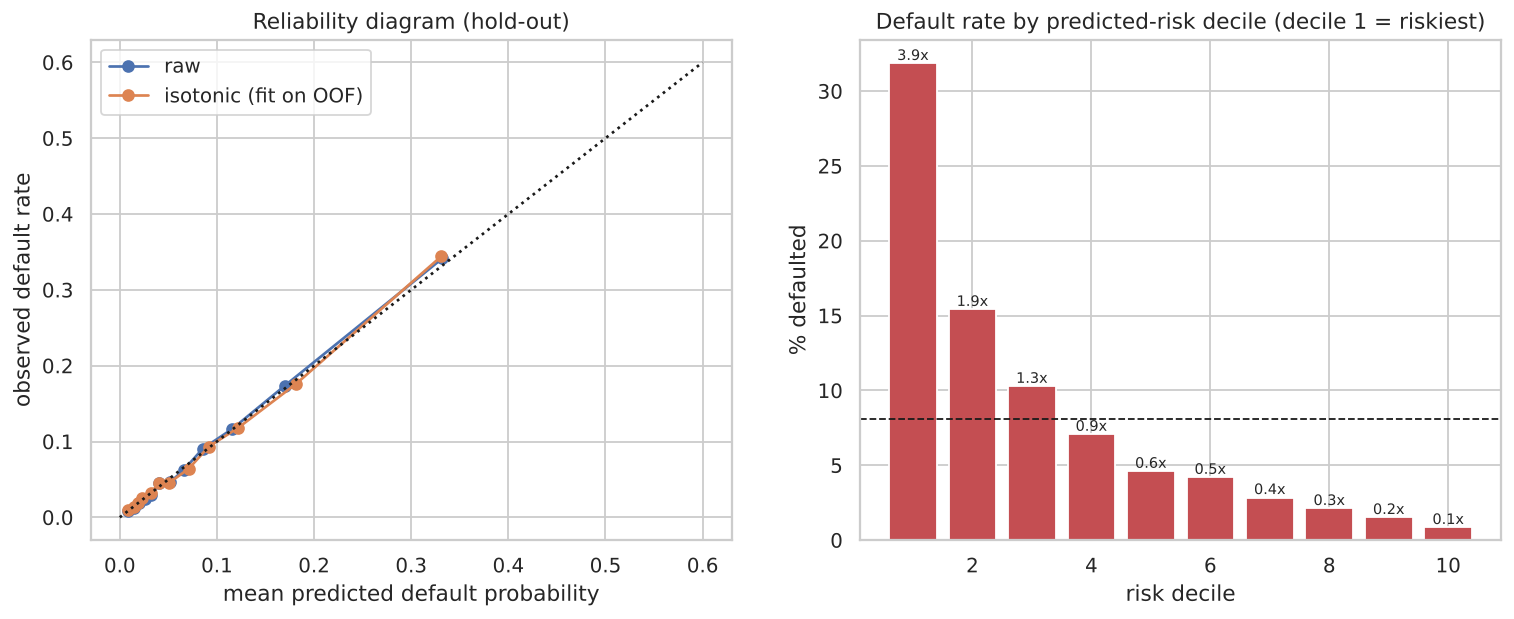

,decile,n,defaults,default_rate,mean_pred,lift,capture_rate,cum_capture_rate
0,1,6151,1959,0.318,0.311,3.945,0.395,0.395
1,2,6150,948,0.154,0.150,1.909,0.191,0.585
2,3,6150,632,0.103,0.099,1.273,0.127,0.713
3,4,6150,435,0.071,0.071,0.876,0.088,0.800
4,5,6151,283,0.046,0.053,0.570,0.057,0.857
5,6,6150,258,0.042,0.040,0.520,0.052,0.909
6,7,6150,175,0.028,0.030,0.352,0.035,0.945
7,8,6150,130,0.021,0.023,0.262,0.026,0.971
8,9,6150,93,0.015,0.016,0.187,0.019,0.990
9,10,6151,52,0.008,0.009,0.105,0.010,1.000


In [11]:
display(Image(F + '11_calibration_and_lift.png')); pd.read_csv(T + '22_lift_table_holdout.csv').round(3)

Predictions are already calibrated, and the riskiest decile has a 31.8% default rate (3.9x average) and holds 39.5% of defaulters.

## 10. What drives predictions?

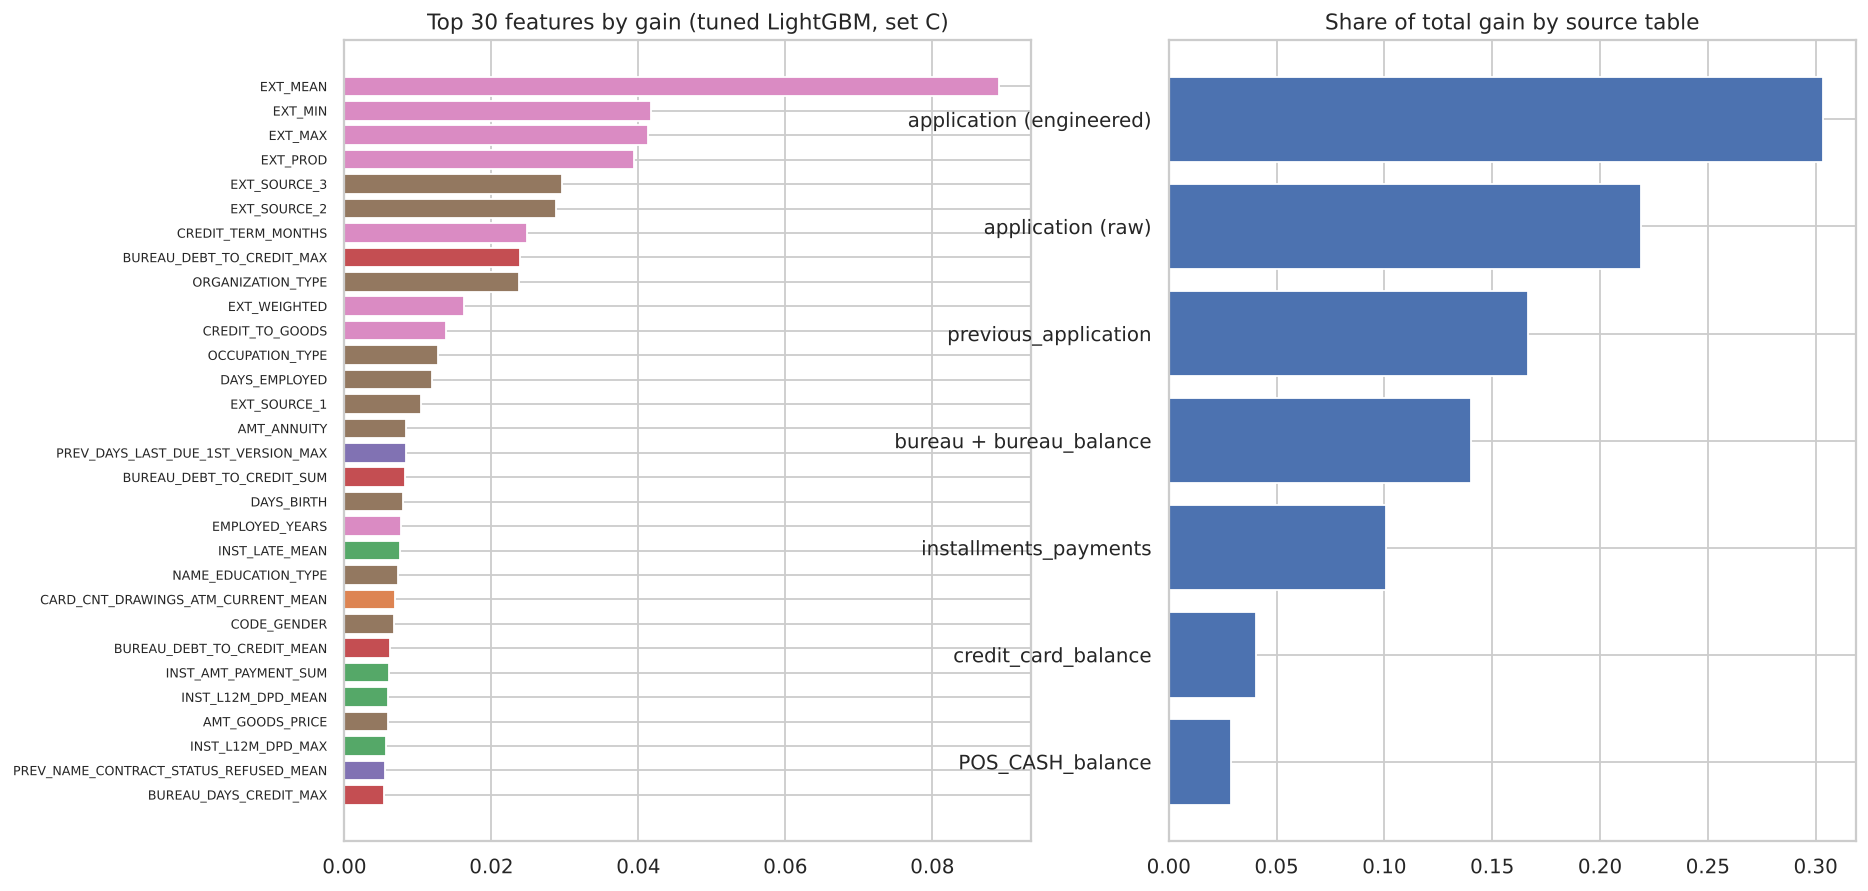

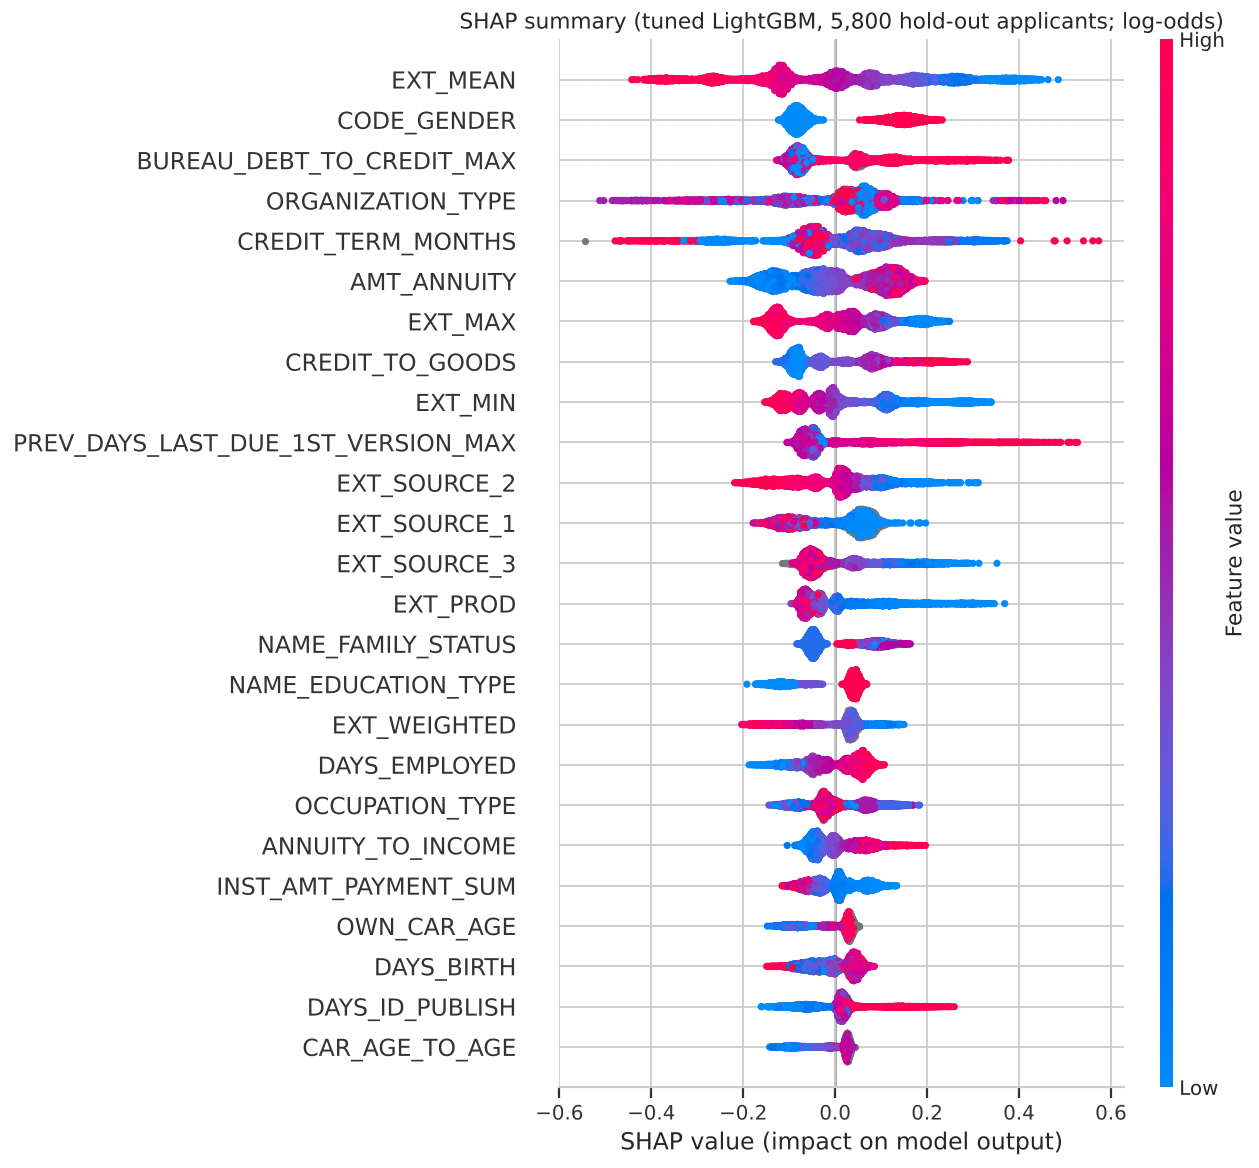

In [12]:
display(Image(F + '12_feature_importance.png')); display(Image(F + '13_shap_summary.png'))

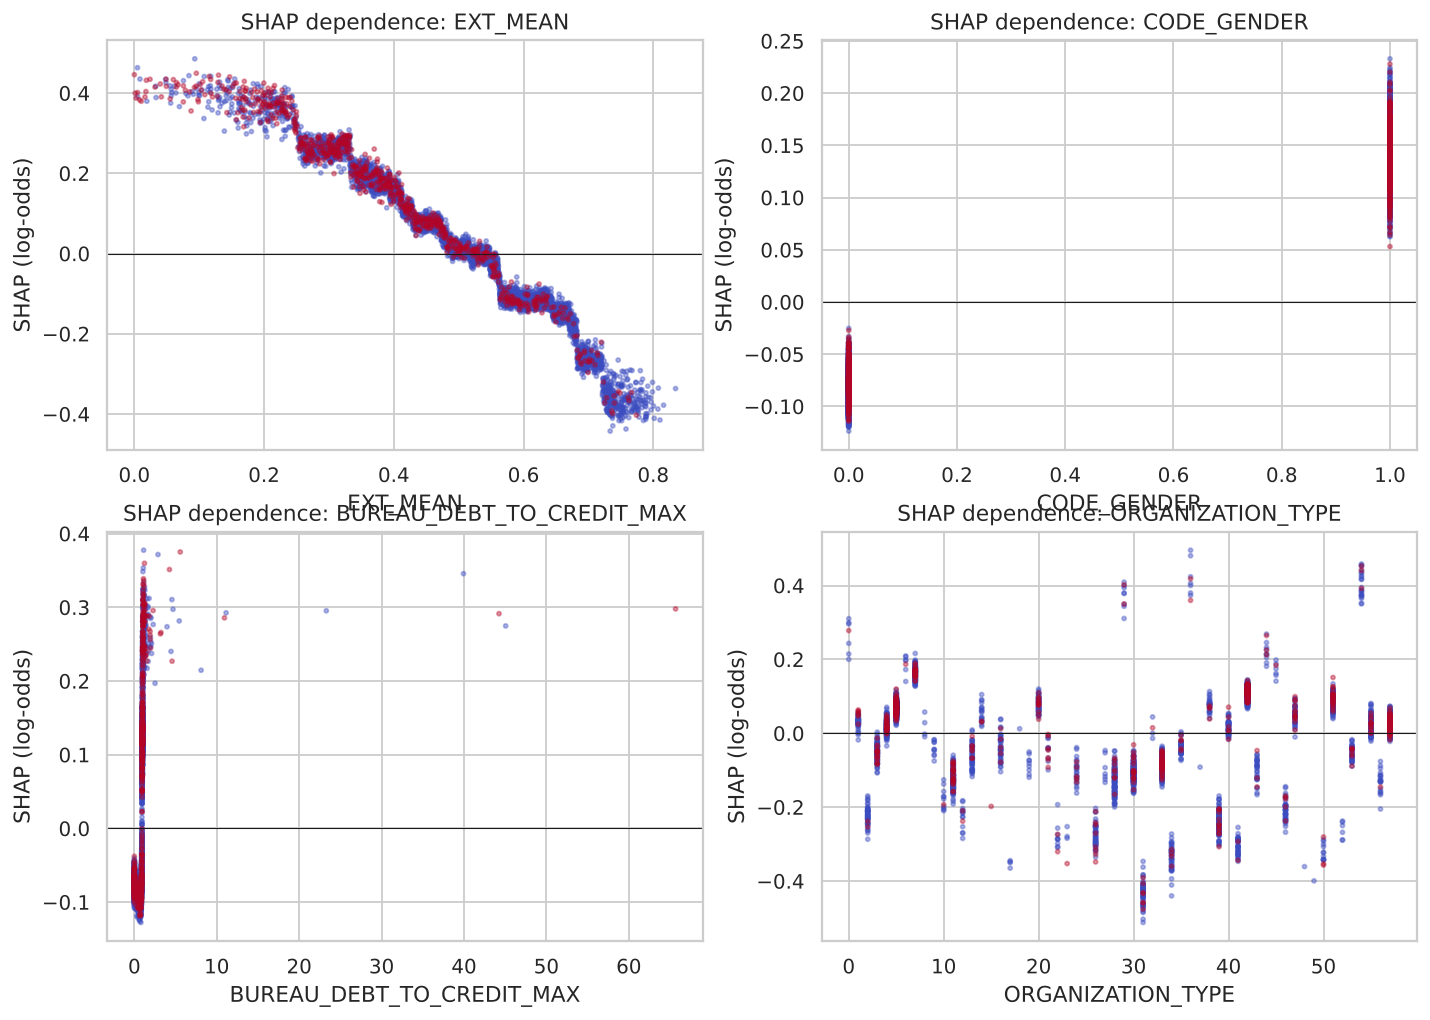

,mean_share,std_share
EXT_MEAN,0.0857,0.0032
EXT_MIN,0.0416,0.0016
EXT_MAX,0.0393,0.0013
EXT_PROD,0.0370,0.0018
EXT_SOURCE_2,0.0278,0.0012
EXT_SOURCE_3,0.0275,0.0008
ORGANIZATION_TYPE,0.0241,0.0009
BUREAU_DEBT_TO_CREDIT_MAX,0.0236,0.0014


In [13]:
display(Image(F + '15_shap_dependence_top4.png')); pd.read_csv(T + '24_importance_stability_across_folds.csv', index_col=0).head(8).round(4)

External scores dominate; high external scores, longer loan terms and higher education reduce risk; high bureau debt-to-credit and credit-to-goods ratios raise it. The top features are stable across folds.

## 11. Sensitive attributes and key features

In [14]:
display(pd.read_csv(T + '40_ablation_sensitive_and_key_features.csv').round(4)); display(pd.read_csv(T + '41_gender_group_metrics.csv').round(3))

,variant,n_features,holdout_auc,ci_low,ci_high
0,full model,688,0.7955,0.7900,0.8019
1,without CODE_GENDER,687,0.7941,0.7884,0.8003
2,without gender and age proxies,681,0.7924,0.7866,0.7988
3,without external scores (EXT_*),678,0.7749,0.7690,0.7818


,variant,gender,n,actual_default_rate,mean_predicted,flagged_share_top20,recall_top20,auc
0,full model,F,40561,0.070,0.070,0.163,0.529,0.789
1,full model,M,20940,0.102,0.099,0.272,0.660,0.795
2,without CODE_GENDER,F,40561,0.070,0.073,0.174,0.548,0.789
3,without CODE_GENDER,M,20940,0.102,0.094,0.251,0.630,0.793
4,without gender and age proxies,F,40561,0.070,0.073,0.173,0.542,0.787
5,without gender and age proxies,M,20940,0.102,0.094,0.252,0.637,0.791
6,without external scores (EXT_*),F,40561,0.070,0.070,0.161,0.488,0.769
7,without external scores (EXT_*),M,20940,0.102,0.099,0.276,0.630,0.772


Dropping gender costs 0.0014 AUC and dropping gender and age proxies 0.0031; dropping the external scores costs 0.021 (secondary tables partly compensate). Flag-rate gaps by gender narrow only partly, because the data genuinely show different default rates and other features act as proxies.

## 12. Error analysis

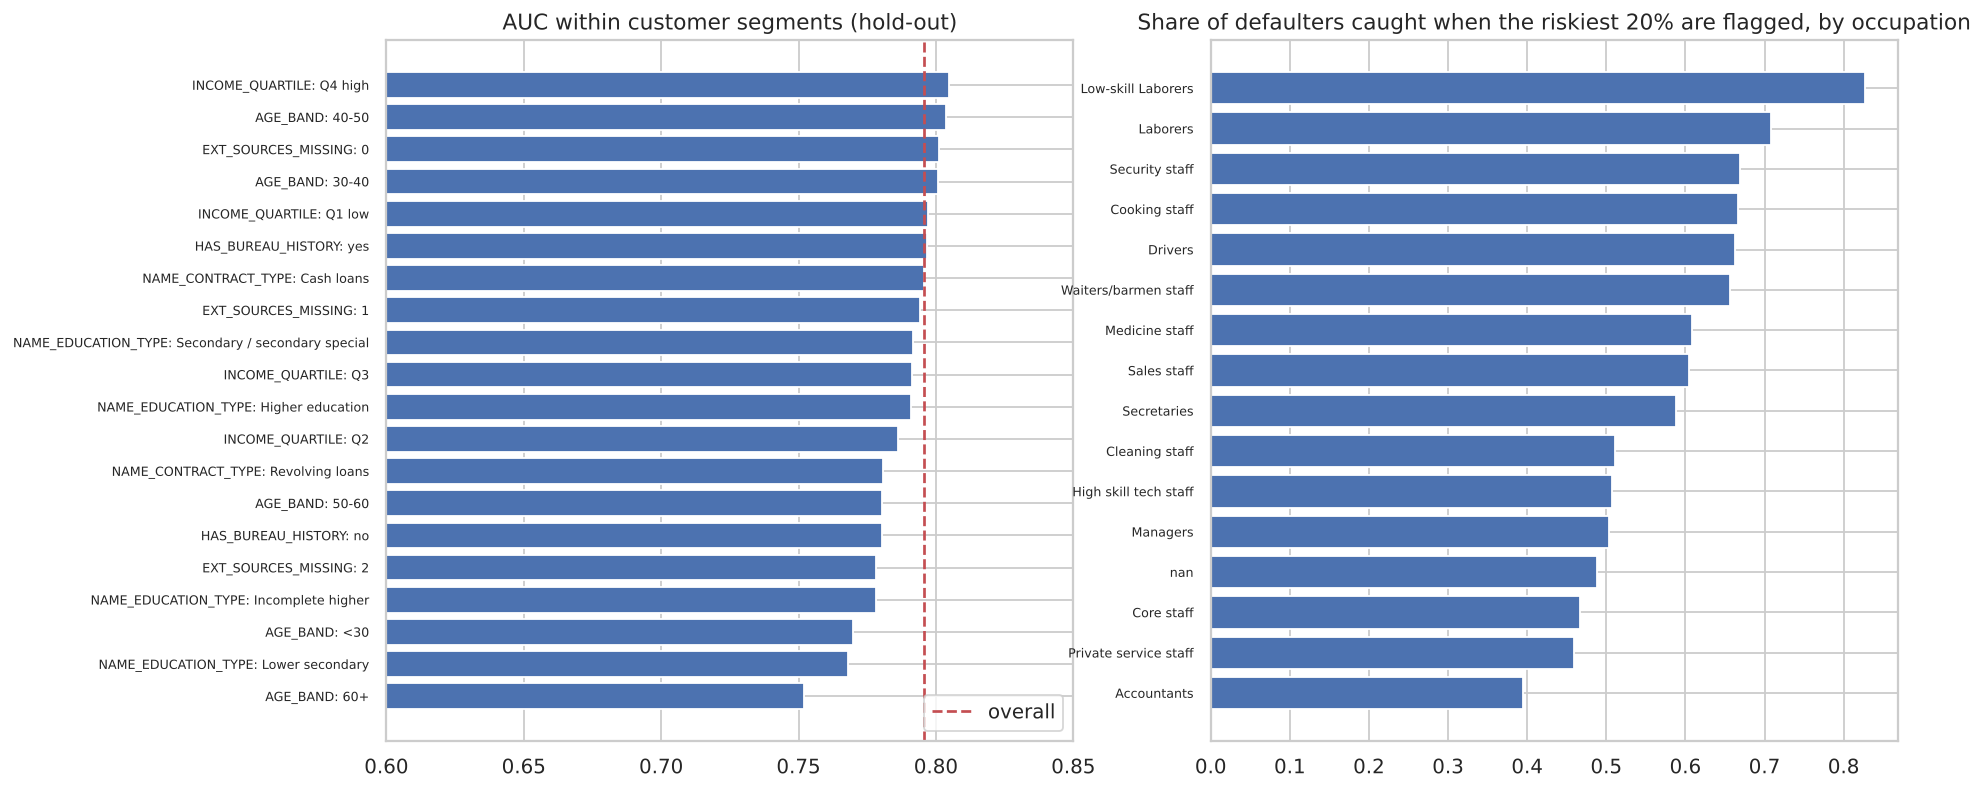

,missed_defaulters_(safest_50%),caught_defaulters_(riskiest_20%),all_repaid
EXT_MEAN,0.588,0.321,0.535
AGE_YEARS,47.554,37.084,43.500
CREDIT_TO_INCOME,3.415,3.160,3.248
ANNUITY_TO_INCOME,0.159,0.174,0.162
EMPLOYED_YEARS,5.218,2.858,4.635
AMT_INCOME_TOTAL,157500.000,135000.000,148500.000
BUREAU_COUNT,4.000,4.000,4.000
PREV_COUNT,4.000,4.000,4.000
INST_DPD_MEAN,0.000,0.207,0.032
n_applicants,708.000,2907.000,56538.000


In [15]:
display(Image(F + '16_segment_error_analysis.png')); pd.read_csv(T + '27_missed_vs_caught_defaulters.csv', index_col=0).round(3)

Calibration holds inside every segment, but the share of defaulters caught when flagging the riskiest 20% varies from 31% (age 60+) to 71% (laborers). Defaulters in the safest half look like repaying customers on every observed feature.

## 13. Learning curve, seeds

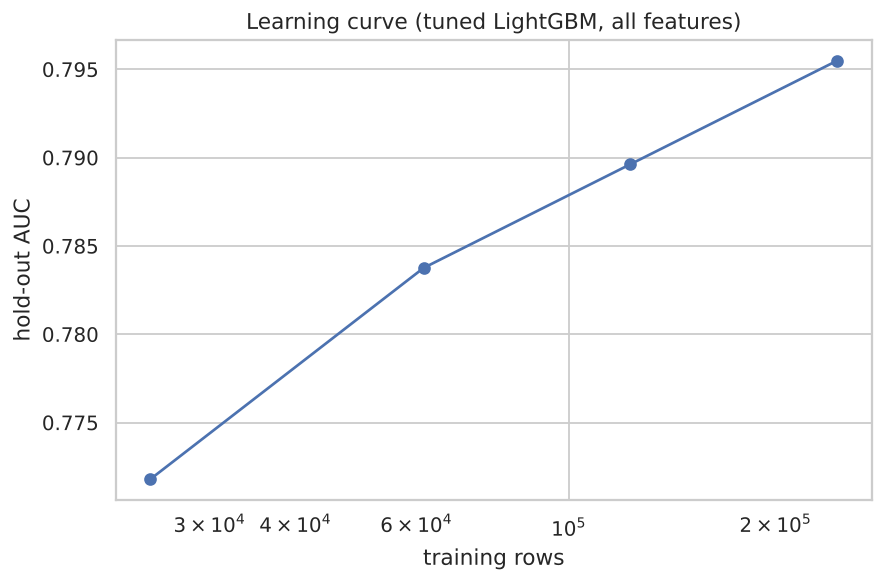

hold-out AUC over 3 seeds: [0.7959, 0.7947, 0.7959]


In [16]:
display(Image(F + '17_learning_curve.png')); print('hold-out AUC over 3 seeds:', [round(x, 4) for x in s['holdout_auc_3_seeds']])

AUC is still rising at 100% of the training data, so more data would help.

## 14. Conclusion
Tuned LightGBM on all tables: hold-out AUC 0.7955. Most of the gain came from relevant data (secondary tables), not from the model or tuning.